# Customer Behaviour & 90-Day Churn-Risk Analysis

This notebook combines the original retail exploratory analysis with a more defensible churn-modelling workflow.

## Business questions
1. What patterns appear in sales, products, countries, and customer value?
2. Which customers have become inactive, based on an explicit recency rule?
3. Can customer behaviour observed at an earlier date help identify customers who make **no purchase in the following 90 days**?
4. Which currently active customers should be reviewed first for retention outreach?

## Important interpretation
In this notebook, “churn” is operationally defined as **no recorded purchase during the 90 days after a snapshot date**. This is a measurable future outcome, not proof that a customer has permanently left. A customer may return later.

The data ends in December 2011, so this is a historical case study—not a live or production-ready churn system. Model quality must be assessed on later snapshot periods that were not used for fitting.

All charts are saved automatically to `assets/charts/` when the notebook is run.

## 1. Imports and configuration

The notebook uses relative paths so it can run in the same folder as `Online Retail(1).xlsx`. Change `DATA_PATH` if your workbook has a different name or location.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, precision_score, recall_score, f1_score,
    roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
CHURN_HORIZON_DAYS = 90
DATA_PATH = Path("Online Retail(1).xlsx")

# All figures are saved relative to the project root for use in the README.
CHARTS_DIR = Path("assets") / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 2. Load the data and check its quality

We preserve a raw copy and report how many rows are removed at each cleaning step. Cancelled invoices, missing customer IDs, non-positive quantities/prices, and exact duplicate rows are excluded from the customer-purchase analysis. These choices are explicit so they can be reviewed rather than hidden.

In [2]:
if not DATA_PATH.exists():
    alternatives = [Path("Online Retail.xlsx"), Path("/mnt/data/Online Retail(1).xlsx")]
    DATA_PATH = next((path for path in alternatives if path.exists()), DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not find the retail workbook. Put it next to this notebook "
        "or update DATA_PATH."
    )

raw = pd.read_excel(DATA_PATH)
print(f"Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())
display(raw.dtypes.rename("dtype").to_frame())

Raw shape: 541,909 rows × 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom


,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


In [3]:
required_columns = {
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
}
missing_columns = required_columns - set(raw.columns)
if missing_columns:
    raise ValueError(f"Required columns missing from workbook: {sorted(missing_columns)}")

quality_counts = []
working = raw.copy()

quality_counts.append(("Raw rows", len(working)))
working = working.drop_duplicates()
quality_counts.append(("After removing exact duplicate rows", len(working)))

working["InvoiceNo"] = working["InvoiceNo"].astype("string").str.strip()
working["InvoiceDate"] = pd.to_datetime(working["InvoiceDate"], errors="coerce")
working["CustomerID"] = pd.to_numeric(working["CustomerID"], errors="coerce")
working["Quantity"] = pd.to_numeric(working["Quantity"], errors="coerce")
working["UnitPrice"] = pd.to_numeric(working["UnitPrice"], errors="coerce")

working = working.dropna(subset=[
    "InvoiceNo", "InvoiceDate", "CustomerID", "Quantity", "UnitPrice"
])
quality_counts.append(("After removing rows missing key fields", len(working)))

is_cancelled = working["InvoiceNo"].str.startswith("C", na=False)
working = working.loc[~is_cancelled].copy()
quality_counts.append(("After excluding cancellation invoices", len(working)))

working = working.loc[
    (working["Quantity"] > 0) & (working["UnitPrice"] > 0)
].copy()
quality_counts.append(("After requiring positive quantity and unit price", len(working)))

working["CustomerID"] = working["CustomerID"].astype("int64")
working["Sales"] = working["Quantity"] * working["UnitPrice"]
working["Hour"] = working["InvoiceDate"].dt.hour
working["DayOfWeek"] = working["InvoiceDate"].dt.day_name()

quality_report = pd.DataFrame(quality_counts, columns=["Cleaning step", "Rows remaining"])
quality_report["Rows removed at step"] = quality_report["Rows remaining"].shift(1) - quality_report["Rows remaining"]
quality_report["Rows removed at step"] = quality_report["Rows removed at step"].fillna(0).astype(int)
display(quality_report)
print(f"Analysis period: {working['InvoiceDate'].min()} to {working['InvoiceDate'].max()}")
print(f"Customers retained: {working['CustomerID'].nunique():,}")
print(f"Distinct invoices retained: {working['InvoiceNo'].nunique():,}")

,Cleaning step,Rows remaining,Rows removed at step
0,Raw rows,541909,0
1,After removing exact duplicate rows,536641,5268
2,After removing rows missing key fields,401604,135037
3,After excluding cancellation invoices,392732,8872
4,After requiring positive quantity and unit price,392692,40


Analysis period: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Customers retained: 4,338
Distinct invoices retained: 18,532


## 3. Exploratory data analysis

Sales are calculated as `Quantity × UnitPrice`. The source workbook does not include an explicit currency field, so charts label values as **dataset currency** rather than assuming a currency symbol.

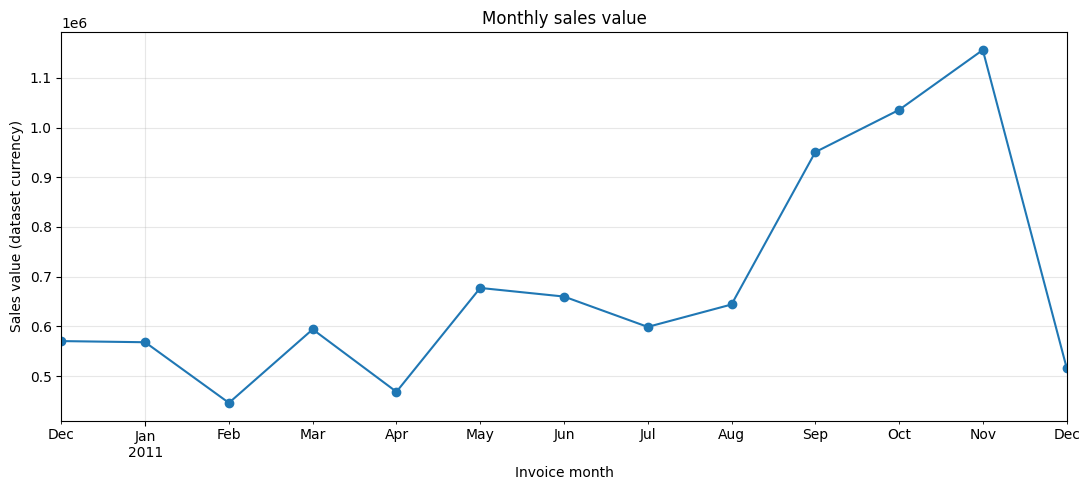

Highest-sales month: 2011-11 (1,156,205.61 dataset currency)


In [4]:
monthly_sales = (
    working.set_index("InvoiceDate")["Sales"]
    .resample("ME").sum()
)

plt.figure(figsize=(11, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly sales value")
plt.xlabel("Invoice month")
plt.ylabel("Sales value (dataset currency)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "monthly_sales.png", dpi=160, bbox_inches="tight")
plt.show()

print("Highest-sales month:", monthly_sales.idxmax().strftime("%Y-%m"),
      f"({monthly_sales.max():,.2f} dataset currency)")

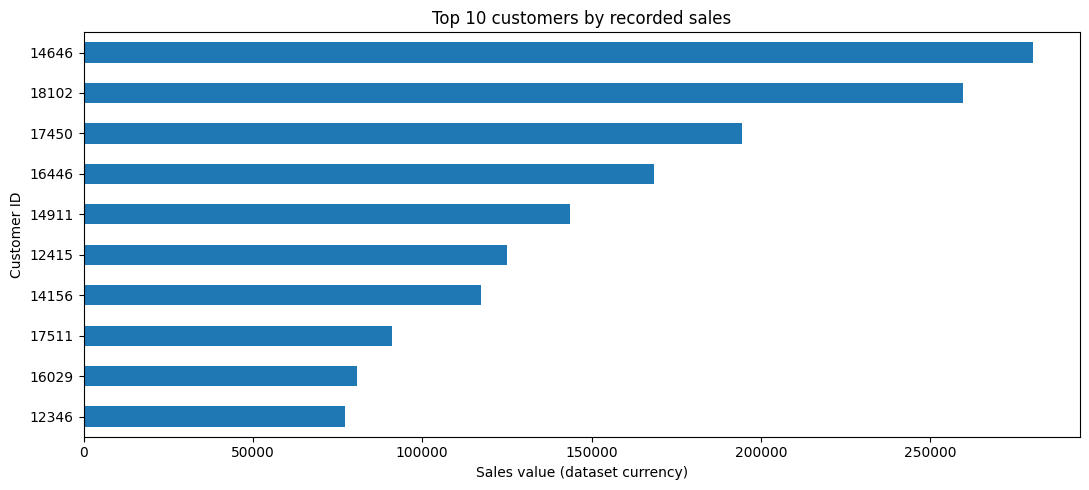

,sales_value
CustomerID,
14646,"280,206.020"
18102,"259,657.300"
17450,"194,390.790"
16446,"168,472.500"
14911,"143,711.170"
12415,"124,914.530"
14156,"117,210.080"
17511,"91,062.380"
16029,"80,850.840"


In [5]:
top_customers = (
    working.groupby("CustomerID")["Sales"].sum()
    .sort_values(ascending=False).head(10)
)
plt.figure(figsize=(11, 5))
top_customers.sort_values().plot(kind="barh")
plt.title("Top 10 customers by recorded sales")
plt.xlabel("Sales value (dataset currency)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top_customers.png", dpi=160, bbox_inches="tight")
plt.show()
display(top_customers.rename("sales_value").to_frame())

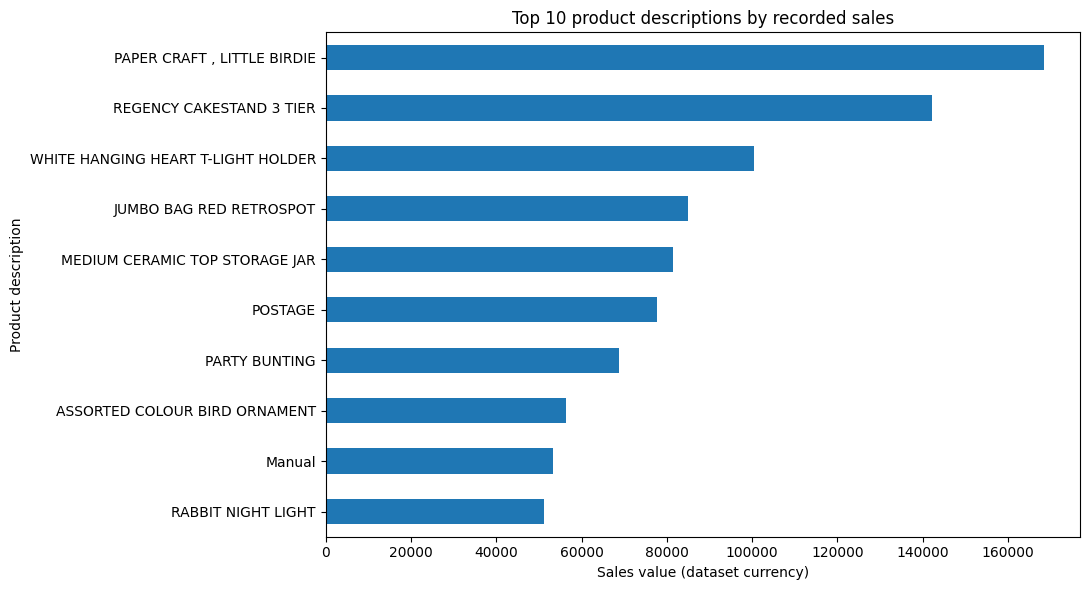

,sales_value
Description,
"PAPER CRAFT , LITTLE BIRDIE","168,469.600"
REGENCY CAKESTAND 3 TIER,"142,264.750"
WHITE HANGING HEART T-LIGHT HOLDER,"100,392.100"
JUMBO BAG RED RETROSPOT,"85,040.540"
MEDIUM CERAMIC TOP STORAGE JAR,"81,416.730"
POSTAGE,"77,803.960"
PARTY BUNTING,"68,785.230"
ASSORTED COLOUR BIRD ORNAMENT,"56,413.030"
Manual,"53,419.930"


In [6]:
top_products = (
    working.groupby("Description", dropna=False)["Sales"].sum()
    .sort_values(ascending=False).head(10)
)
plt.figure(figsize=(11, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 product descriptions by recorded sales")
plt.xlabel("Sales value (dataset currency)")
plt.ylabel("Product description")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top_products.png", dpi=160, bbox_inches="tight")
plt.show()
display(top_products.rename("sales_value").to_frame())

,sales_value
Country,
United Kingdom,"7,285,024.644"
Netherlands,"285,446.340"
EIRE,"265,262.460"
Germany,"228,678.400"
France,"208,934.310"
Australia,"138,453.810"
Spain,"61,558.560"
Switzerland,"56,443.950"
Belgium,"41,196.340"


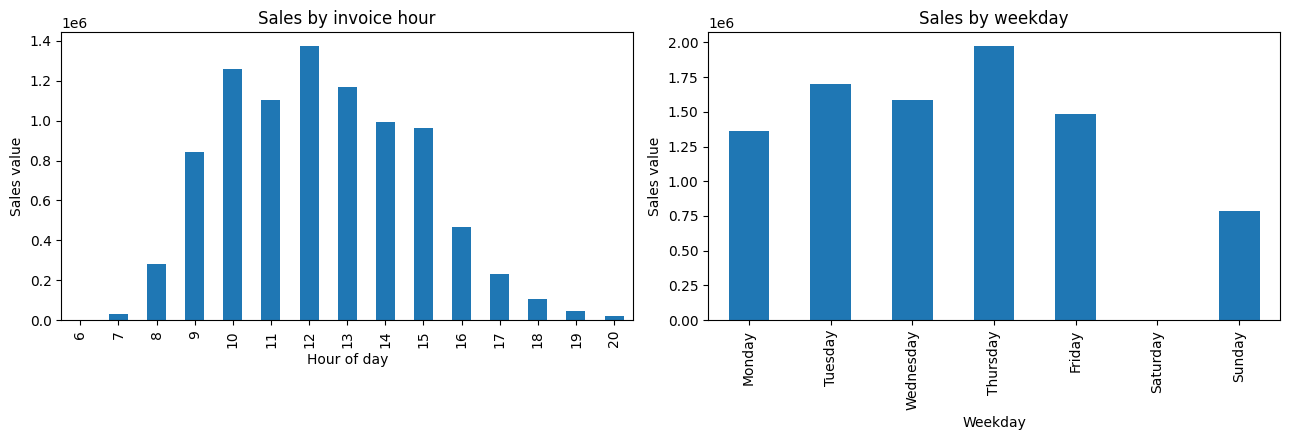

Highest-sales hour: 12:00
Highest-sales weekday: Thursday


In [7]:
country_sales = (
    working.groupby("Country")["Sales"].sum()
    .sort_values(ascending=False)
)
display(country_sales.head(10).rename("sales_value").to_frame())

hour_sales = working.groupby("Hour")["Sales"].sum()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sales = working.groupby("DayOfWeek")["Sales"].sum().reindex(weekday_order)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
hour_sales.plot(kind="bar", ax=axes[0])
axes[0].set_title("Sales by invoice hour")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Sales value")
weekday_sales.plot(kind="bar", ax=axes[1])
axes[1].set_title("Sales by weekday")
axes[1].set_xlabel("Weekday")
axes[1].set_ylabel("Sales value")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "sales_by_hour_and_weekday.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"Highest-sales hour: {hour_sales.idxmax():02d}:00")
print(f"Highest-sales weekday: {weekday_sales.idxmax()}")

## 4. Customer-level RFM summary

We calculate:
- **Recency:** days since the last purchase, relative to the day after the final date in the dataset.
- **Frequency:** number of distinct invoices/orders, not number of product-line rows.
- **Monetary:** total recorded sales value.
- **Average order value:** monetary value divided by distinct invoices.
- **Tenure:** days between the customer's first purchase and the reference date.
- **Product variety:** number of distinct stock codes purchased.

This full-period summary is useful for retrospective segmentation. It must **not** be used to train a model that claims to predict the past: the predictive model below builds separate feature snapshots using only transactions available before each snapshot date.

In [8]:
reference_date = working["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = (
    working.groupby("CustomerID")
    .agg(
        last_purchase=("InvoiceDate", "max"),
        first_purchase=("InvoiceDate", "min"),
        frequency=("InvoiceNo", "nunique"),
        monetary=("Sales", "sum"),
        unique_products=("StockCode", "nunique"),
        transaction_rows=("InvoiceNo", "size"),
        country=("Country", lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown"),
    )
    .reset_index()
)
rfm["recency"] = (reference_date - rfm["last_purchase"].dt.normalize()).dt.days
rfm["tenure_days"] = (reference_date - rfm["first_purchase"].dt.normalize()).dt.days
rfm["avg_order_value"] = rfm["monetary"] / rfm["frequency"].clip(lower=1)
rfm["inactive_90_days_at_dataset_end"] = (rfm["recency"] > CHURN_HORIZON_DAYS).astype(int)

display(rfm.sort_values("monetary", ascending=False).head(10))
print(f"Customers in RFM summary: {len(rfm):,}")
print(
    "Customers with >90 days since last recorded purchase:",
    f"{rfm['inactive_90_days_at_dataset_end'].sum():,}",
    f"({rfm['inactive_90_days_at_dataset_end'].mean():.1%})"
)

,CustomerID,last_purchase,first_purchase,frequency,monetary,unique_products,transaction_rows,country,recency,tenure_days,avg_order_value,inactive_90_days_at_dataset_end
1689,14646,2011-12-08 12:12:00,2010-12-20 10:09:00,73,"280,206.020",700,2076,Netherlands,2,355,"3,838.439",0
4201,18102,2011-12-09 11:50:00,2010-12-07 16:42:00,60,"259,657.300",150,431,United Kingdom,1,368,"4,327.622",0
3728,17450,2011-12-01 13:29:00,2010-12-07 09:23:00,46,"194,390.790",124,336,United Kingdom,9,368,"4,225.887",0
3008,16446,2011-12-09 09:15:00,2011-05-18 09:52:00,2,"168,472.500",3,3,United Kingdom,1,206,"84,236.250",0
1879,14911,2011-12-08 15:54:00,2010-12-01 14:05:00,201,"143,711.170",1787,5670,EIRE,2,374,714.981,0
55,12415,2011-11-15 14:22:00,2011-01-06 11:12:00,21,"124,914.530",444,714,Australia,25,338,"5,948.311",0
1333,14156,2011-11-30 10:54:00,2010-12-03 11:48:00,55,"117,210.080",714,1395,EIRE,10,372,"2,131.092",0
3771,17511,2011-12-07 10:12:00,2010-12-01 10:19:00,31,"91,062.380",453,963,United Kingdom,3,374,"2,937.496",0
2702,16029,2011-11-01 10:27:00,2010-12-01 09:57:00,63,"80,850.840",44,241,United Kingdom,39,374,"1,283.347",0
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,"77,183.600",1,1,United Kingdom,326,326,"77,183.600",1


Customers in RFM summary: 4,338
Customers with >90 days since last recorded purchase: 1,449 (33.4%)


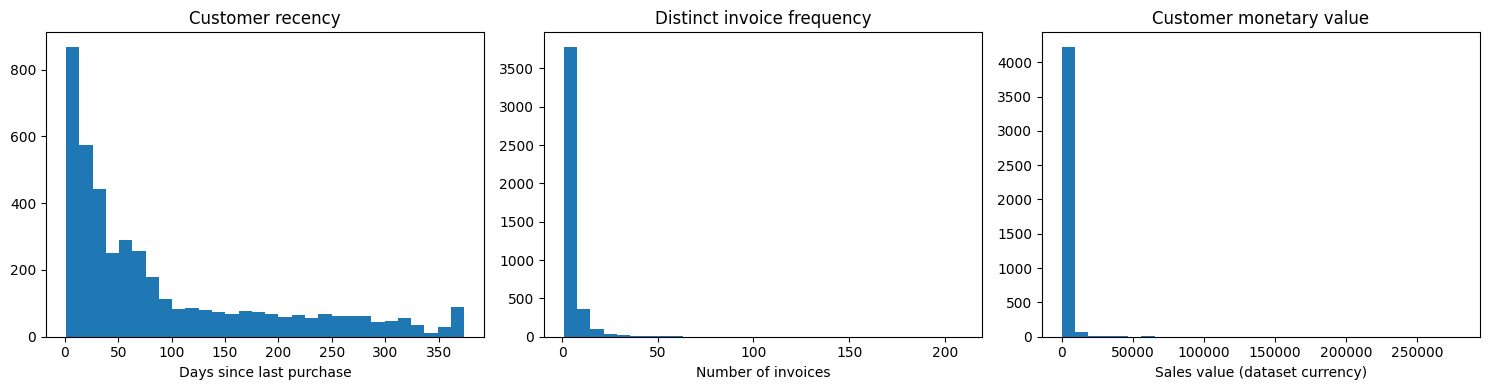

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(rfm["recency"], bins=30)
axes[0].set_title("Customer recency")
axes[0].set_xlabel("Days since last purchase")
axes[1].hist(rfm["frequency"], bins=30)
axes[1].set_title("Distinct invoice frequency")
axes[1].set_xlabel("Number of invoices")
axes[2].hist(rfm["monetary"], bins=30)
axes[2].set_title("Customer monetary value")
axes[2].set_xlabel("Sales value (dataset currency)")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "rfm_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Define a forward-looking 90-day outcome

Instead of labelling customers as churned from their final recency and then asking a model to reproduce that same label, we create historical snapshots.

For each snapshot date:
1. Features use transactions strictly **before** the snapshot date.
2. The outcome is `1` if the customer makes **no purchase during the following 90 days**; otherwise it is `0`.
3. Only snapshots with a fully observed 90-day outcome window are retained.

This is a more appropriate prediction setup. It still measures 90-day purchase inactivity—not permanent churn—and a single dataset cannot prove that the model will perform equally well in another business or time period.

In [10]:
data_end = working["InvoiceDate"].max()
# Month-start snapshots; last snapshot must have a fully observed 90-day outcome window.
candidate_dates = pd.date_range("2011-03-01", "2011-09-01", freq="MS")
snapshot_dates = [
    date for date in candidate_dates
    if date + pd.Timedelta(days=CHURN_HORIZON_DAYS) <= data_end.normalize() + pd.Timedelta(days=1)
]
print("Snapshot dates:", [d.strftime("%Y-%m-%d") for d in snapshot_dates])
print("Latest transaction:", data_end)

Snapshot dates: ['2011-03-01', '2011-04-01', '2011-05-01', '2011-06-01', '2011-07-01', '2011-08-01', '2011-09-01']
Latest transaction: 2011-12-09 12:50:00


In [11]:
FEATURES = [
    "recency", "frequency", "monetary",
    "avg_order_value", "tenure_days", "unique_products"
]

def make_snapshot(data: pd.DataFrame, snapshot_date: pd.Timestamp) -> pd.DataFrame:
    """Build customer features before snapshot_date and label the next 90 days."""
    history = data.loc[data["InvoiceDate"] < snapshot_date].copy()
    future_end = snapshot_date + pd.Timedelta(days=CHURN_HORIZON_DAYS)
    future = data.loc[
        (data["InvoiceDate"] >= snapshot_date) &
        (data["InvoiceDate"] < future_end)
    ]

    if history.empty:
        return pd.DataFrame()

    features = (
        history.groupby("CustomerID")
        .agg(
            last_purchase=("InvoiceDate", "max"),
            first_purchase=("InvoiceDate", "min"),
            frequency=("InvoiceNo", "nunique"),
            monetary=("Sales", "sum"),
            unique_products=("StockCode", "nunique"),
        )
        .reset_index()
    )
    features["recency"] = (
        snapshot_date.normalize() - features["last_purchase"].dt.normalize()
    ).dt.days
    features["tenure_days"] = (
        snapshot_date.normalize() - features["first_purchase"].dt.normalize()
    ).dt.days
    features["avg_order_value"] = (
        features["monetary"] / features["frequency"].clip(lower=1)
    )

    future_customers = set(future["CustomerID"].unique())
    features["no_purchase_next_90_days"] = (
        ~features["CustomerID"].isin(future_customers)
    ).astype(int)
    features["snapshot_date"] = snapshot_date
    return features[["CustomerID", "snapshot_date", *FEATURES, "no_purchase_next_90_days"]]

snapshots = pd.concat(
    [make_snapshot(working, date) for date in snapshot_dates],
    ignore_index=True
)
if snapshots.empty:
    raise ValueError("No valid historical snapshots were created. Check the date range.")

snapshot_summary = (
    snapshots.groupby("snapshot_date")
    .agg(
        customers=("CustomerID", "nunique"),
        churn_rate=("no_purchase_next_90_days", "mean"),
        churned=("no_purchase_next_90_days", "sum")
    )
    .reset_index()
)
display(snapshot_summary)

,snapshot_date,customers,churn_rate,churned
0,2011-03-01,1682,0.433,728
1,2011-04-01,2134,0.458,977
2,2011-05-01,2434,0.461,1122
3,2011-06-01,2718,0.507,1378
4,2011-07-01,2960,0.505,1494
5,2011-08-01,3148,0.481,1515
6,2011-09-01,3317,0.438,1453


## 6. Train/test split by time

Earlier snapshots are used for training; later snapshots are held out for testing. This is closer to the real use case—learning from earlier customer behaviour and evaluating on a later period—than a random split of one end-of-dataset label.

The test set contains later customer snapshots, and customers may appear in both periods because a deployed business system can observe existing customers over time. No feature for a snapshot uses transactions from that snapshot's future outcome window.

In [12]:
if len(snapshot_dates) < 4:
    raise ValueError("Not enough complete snapshots for a useful temporal split.")

split_position = max(1, int(np.floor(len(snapshot_dates) * 0.6)))
train_dates = snapshot_dates[:split_position]
test_dates = snapshot_dates[split_position:]

train = snapshots[snapshots["snapshot_date"].isin(train_dates)].copy()
test = snapshots[snapshots["snapshot_date"].isin(test_dates)].copy()

X_train = train[FEATURES]
y_train = train["no_purchase_next_90_days"]
X_test = test[FEATURES]
y_test = test["no_purchase_next_90_days"]

print("Training snapshots:", [d.strftime("%Y-%m-%d") for d in train_dates])
print("Testing snapshots:", [d.strftime("%Y-%m-%d") for d in test_dates])
print(f"Train rows: {len(train):,}; positive outcome rate: {y_train.mean():.1%}")
print(f"Test rows:  {len(test):,}; positive outcome rate: {y_test.mean():.1%}")

Training snapshots: ['2011-03-01', '2011-04-01', '2011-05-01', '2011-06-01']
Testing snapshots: ['2011-07-01', '2011-08-01', '2011-09-01']
Train rows: 8,968; positive outcome rate: 46.9%
Test rows:  9,425; positive outcome rate: 47.3%


## 7. Fit baseline, Logistic Regression, and Random Forest

The baseline predicts the most common class. Logistic Regression uses a pipeline so imputation and scaling are fitted only on training data and applied consistently to the test set. Random Forest is also evaluated on the same chronological holdout.

Accuracy alone can be misleading when classes are imbalanced. We report precision, recall, F1, ROC-AUC, and average precision (PR-AUC). ROC-AUC and average precision are only reported when the test set contains both outcome classes.

In [13]:
models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

fitted_models = {}
metric_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    pred = model.predict(X_test)
    probability = (
        model.predict_proba(X_test)[:, 1]
        if hasattr(model, "predict_proba") else None
    )
    row = {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision_churn": precision_score(y_test, pred, zero_division=0),
        "recall_churn": recall_score(y_test, pred, zero_division=0),
        "f1_churn": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probability) if probability is not None and y_test.nunique() == 2 else np.nan,
        "average_precision": average_precision_score(y_test, probability) if probability is not None and y_test.nunique() == 2 else np.nan,
    }
    metric_rows.append(row)

metrics = pd.DataFrame(metric_rows).set_index("model")
display(metrics.sort_values("average_precision", ascending=False, na_position="last").round(3))

,accuracy,precision_churn,recall_churn,f1_churn,roc_auc,average_precision
model,,,,,,
Random Forest,0.687,0.650,0.735,0.690,0.755,0.692
Logistic Regression,0.689,0.654,0.729,0.689,0.749,0.679
Majority-class baseline,0.527,0.000,0.000,0.000,0.500,0.473


Classification report — Random Forest
                             precision    recall  f1-score   support

  Purchased in next 90 days       0.73      0.64      0.68      4963
No purchase in next 90 days       0.65      0.74      0.69      4462

                   accuracy                           0.69      9425
                  macro avg       0.69      0.69      0.69      9425
               weighted avg       0.69      0.69      0.69      9425



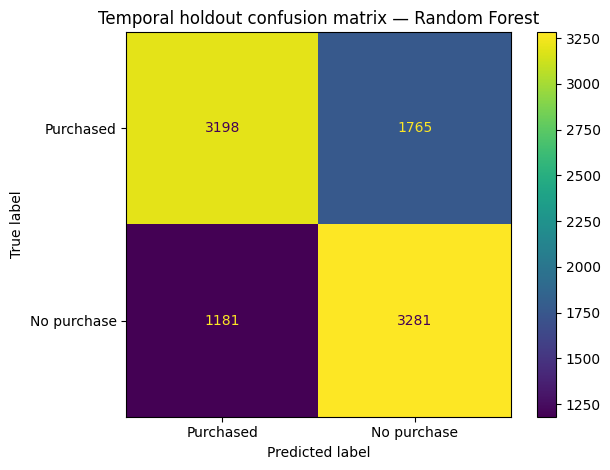

In [14]:
chosen_name = "Random Forest"
chosen_model = fitted_models[chosen_name]
test_predictions = chosen_model.predict(X_test)

print(f"Classification report — {chosen_name}")
print(classification_report(
    y_test, test_predictions,
    labels=[0, 1],
    target_names=["Purchased in next 90 days", "No purchase in next 90 days"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    display_labels=["Purchased", "No purchase"],
    values_format="d"
)
plt.title(f"Temporal holdout confusion matrix — {chosen_name}")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Inspect model behaviour

Feature importance is descriptive, not causal. It indicates which inputs the fitted Random Forest relied on in this run; it does not show that changing a feature would change churn.

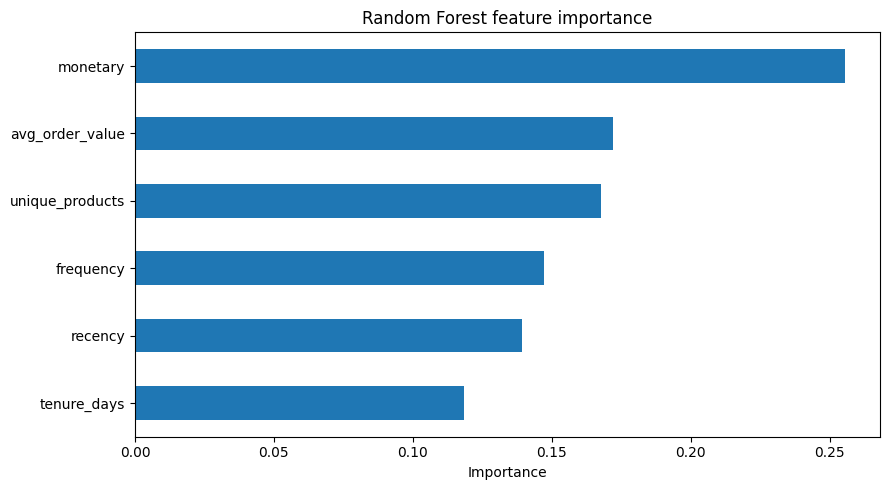

,importance
monetary,0.255
avg_order_value,0.172
unique_products,0.168
frequency,0.147
recency,0.139
tenure_days,0.118


In [15]:
rf_estimator = fitted_models["Random Forest"].named_steps["model"]
importance = pd.Series(rf_estimator.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(9, 5))
importance.plot(kind="barh")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "random_forest_feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()
display(importance.sort_values(ascending=False).rename("importance").to_frame())

## 9. Score customers at the end of the available dataset

For the final operational-style list, features are calculated using all transactions available up to the dataset end. The final model is refitted on all historical snapshots, then scores customers who purchased within the last 90 days of the dataset.

These are **ranking scores for review**, not calibrated probabilities. Because the dataset is historical, this export is a demonstration of workflow rather than a current customer-risk list.

In [16]:
final_reference = working["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
latest_features = (
    working.groupby("CustomerID")
    .agg(
        last_purchase=("InvoiceDate", "max"),
        first_purchase=("InvoiceDate", "min"),
        frequency=("InvoiceNo", "nunique"),
        monetary=("Sales", "sum"),
        unique_products=("StockCode", "nunique"),
    )
    .reset_index()
)
latest_features["recency"] = (
    final_reference - latest_features["last_purchase"].dt.normalize()
).dt.days
latest_features["tenure_days"] = (
    final_reference - latest_features["first_purchase"].dt.normalize()
).dt.days
latest_features["avg_order_value"] = (
    latest_features["monetary"] / latest_features["frequency"].clip(lower=1)
)

final_model = clone(models["Random Forest"])
final_model.fit(snapshots[FEATURES], snapshots["no_purchase_next_90_days"])
latest_features["risk_score"] = final_model.predict_proba(latest_features[FEATURES])[:, 1]
latest_features["inactive_over_90_days"] = (
    latest_features["recency"] > CHURN_HORIZON_DAYS
)

active_at_end = latest_features.loc[
    latest_features["recency"] <= CHURN_HORIZON_DAYS
].copy()
high_priority = active_at_end.sort_values("risk_score", ascending=False).head(50)

output_columns = [
    "CustomerID", "recency", "frequency", "monetary",
    "avg_order_value", "tenure_days", "unique_products", "risk_score"
]
high_priority = high_priority[output_columns]

output_path = Path("high_priority_at_risk_customers_improved.xlsx")
high_priority.to_excel(output_path, index=False)
print(f"Saved {len(high_priority)} customers to: {output_path.resolve()}")
display(high_priority.head(15))

Saved 50 customers to: /mnt/data/high_priority_at_risk_customers_improved.xlsx


,CustomerID,recency,frequency,monetary,avg_order_value,tenure_days,unique_products,risk_score
994,13690,60,1,172.250,172.250,60,9,0.918
1260,14054,66,1,92.460,92.460,66,6,0.905
353,12789,66,1,91.850,91.850,66,4,0.901
3794,17538,26,1,98.420,98.420,26,9,0.897
2255,15419,25,1,135.860,135.860,25,8,0.892
256,12659,30,1,91.680,91.680,30,5,0.890
1180,13947,66,1,90.600,90.600,66,5,0.884
4091,17947,38,1,176.680,176.680,38,9,0.880
2700,16026,44,1,236.090,236.090,44,30,0.880
2087,15195,3,1,"3,861.000","3,861.000",3,1,0.861


## 10. Export supporting analysis tables

These tables make it easier to inspect the results outside the notebook. The workbook includes RFM summaries, snapshot-level outcome rates, temporal test metrics, and the priority customer list.

In [17]:
results_path = Path("customer_churn_analysis_results.xlsx")
with pd.ExcelWriter(results_path, engine="openpyxl") as writer:
    rfm.to_excel(writer, sheet_name="RFM Summary", index=False)
    snapshot_summary.to_excel(writer, sheet_name="Snapshot Outcomes", index=False)
    metrics.reset_index().to_excel(writer, sheet_name="Model Metrics", index=False)
    high_priority.to_excel(writer, sheet_name="Priority Customers", index=False)
    quality_report.to_excel(writer, sheet_name="Data Quality", index=False)

print(f"Saved analysis workbook to: {results_path.resolve()}")

Saved analysis workbook to: /mnt/data/customer_churn_analysis_results.xlsx


## 11. Conclusions and next steps

Before using these scores for real retention decisions:
- Compare model metrics against the majority-class baseline and focus on recall/average precision as well as accuracy.
- Test additional snapshot dates or use a newer dataset; the historical period is short.
- Consider whether 90 days is the right inactivity window for this retail business.
- Review false positives and false negatives with business stakeholders.
- Calibrate predicted probabilities and select a campaign threshold based on retention cost, customer value, and campaign capacity.
- Confirm data licensing and source attribution before redistributing the workbook.

**Do not describe the output as confirmed churn or as a guaranteed probability of churn.** It estimates the risk of no purchase in a 90-day window under this dataset's operational definition.